In [1]:
## Load the required packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import copy
import datetime
import time as thetime # (I know it's messy to rename as 'thetime', but 'time' is used elsewhere)
import operator # So that it is possible to sort a dictionary on the values

import multiprocessing
from multiprocessing import Pool # To run models in multiple threads simultaneously

# To display tables in HTML output
from IPython.display import HTML, display

from statsmodels.tsa.seasonal import seasonal_decompose as sm

# Tell the notebook to do inline charts
%matplotlib inline

# The location of the data
FOOTFALL_FILE = "footfall_data/footfall_data.csv"
WEATHER_FILE = "weather_data/Weather_data.csv"
HOLIDAY_FILE = "holiday_data/Scotland_Bank_Holidays.csv"

c:\Users\Bagya\anaconda3\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\Bagya\anaconda3\lib\site-packages\numpy\.libs\libopenblas.EL2C6PLE4ZYW3ECEVIV3OXXGRN2NRFM2.gfortran-win_amd64.dll
c:\Users\Bagya\anaconda3\lib\site-packages\numpy\.libs\libopenblas.FB5AE2TYXYH2IJRDKGDGQ3XBKLKTF43H.gfortran-win_amd64.dll
  warnings.warn("loaded more than 1 DLL from .libs:"


In [3]:
def process_data(file):
    # Processing Weather data 
    # weather code obtained from https://dev.meteostat.net/
        weather_code = {1:'Clear',2: 'Fair',3:'Cloudy',4:'Overcast',5:'Fog',6: 'Freezing Fog',7:'Light Rain',8:'Rain',9:'Heavy Rain',
        10:'Freezing Rain',11:'Heavy Freezing Rain',12:'Sleet',13:'Heavy Sleet',14:'Light Snowfall',15:'Snowfall',16:'Heavy Snowfall',17:'Rain Shower',
        18:'Heavy Rain Shower',19:'Sleet Shower',20:'Heavy Sleet Shower',21:'Snow Shower',22:'Heavy Snow Shower',23:'Lightning',24:'Hail',25:'Thunderstorm',
        26:'Heavy Thunderstorm',27:'Storm'}
        
        location_dict = {"Argyll Street near Queen Street Junction" : "Argyll St." , "Buchanan Street near Buchanan Galleries Entrance" : "Buchanan St.1",
    "Buchanan Street near Gordon Street Junction" : "Buchanan St.2", "Sauchiehall Street near Wellington Street Junction" : "Sauchiehall St.1",
     "194 Bath Street (near Blythswood Street Junction)" : "Bath Street", "Sauchiehall Street near Elmbank Street Junction" : "Sauchiehall St.2",
     "253 High Street (near George Street Junction)" : "High Street" }
        
        file['LocationName'] = file['LocationName'].map(location_dict) 

        if 'Year' not in file:
            file['Year'] = pd.DatetimeIndex(file['processDate']).year
        if 'Month' not in file:    
            file['Month'] = pd.DatetimeIndex(file['processDate']).month
        if 'Month_yr' not in file:
            file['Month_yr'] = pd.to_datetime(file['processDate']).dt.strftime('%b-%Y')
        if 'BRCWeek' not in file:
            file['BRCWeek'] = pd.to_datetime(file["processDate"]).dt.strftime('%w')
        if 'Week_yr' not in file:
            file['Week_yr'] =  pd.to_datetime(file["processDate"]).dt.strftime('%U-%Y')
        if 'week_no' not in file:
            file['week_no'] =  pd.to_datetime(file["processDate"]).dt.strftime('%U')
        if 'Hour_yr' not in file:
            file['Hour_yr'] =  pd.to_datetime(file["processDate"]).dt.strftime('%H-%Y')
        if 'Hour' not in file:
            file['Hour'] =  pd.to_datetime(file["processDate"]).dt.hour
        if 'NewDate' not in file:
            file['NewDate'] =  pd.to_datetime(file["processDate"])
        if 'Day_yr' not in file:
            file['Day_yr'] =  pd.to_datetime(file["processDate"]).dt.strftime('%A/%d-%b-%Y')
        if 'Day' not in file:
            file['Day'] =  pd.to_datetime(file["processDate"]).dt.strftime('%d')
        
        file['Hour_Min'] =  pd.to_datetime(file["processDate"]).dt.strftime('%H:%M')
        file['NewDate_y'] = pd.to_datetime(file["processDate"]).dt.strftime('%d/%b/%Y')
        file['Date_y'] = pd.to_datetime(file['NewDate_y'] + ' '+file['Hour_Min'])
        weather_file = pd.read_csv(WEATHER_FILE)
        weather_file = weather_file.fillna(0)
        weather_file['weather_condition_code'] = weather_file['weather_condition_code'].astype(int)
        file['Date'] =  pd.to_datetime(file['processDate']).dt.strftime('%d/%m/%Y')
        if 'weather_condition_code_new' not in weather_file:
            weather_file["weather_condition_code_new"] = weather_file['weather_condition_code'].map(weather_code)

        merged_data = pd.merge(file,weather_file[['Date','Hour','Temperature','Relative_Humidity','Percipitation','Wind_Direction','Wind_Speed', 'weather_condition_code','weather_condition_code_new']],on=["Date","Hour"], how='left')
        holiday_file = pd.read_csv(HOLIDAY_FILE)
        merged_data1 = pd.merge(merged_data,holiday_file[['Date','title']],on='Date', how='left')
        merged_data1 = merged_data1.fillna(0)
        return merged_data1

Year
2018    44928
2019    52560
2020    61152
2021    61320
dtype: int64


<AxesSubplot:xlabel='Year'>

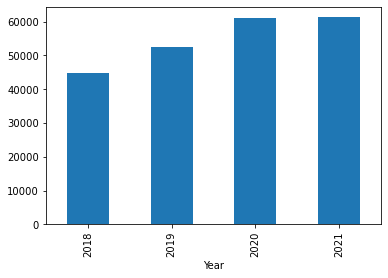

In [4]:
file = pd.read_csv(FOOTFALL_FILE) # reading footfall data
weather_file = pd.read_csv(WEATHER_FILE) # reading weather data
holiday_file = pd.read_csv(HOLIDAY_FILE) # reading holiday data
file = process_data(file) # process_data function has the data-processing functionality
print(file.groupby('Year').size())
file.groupby('Year').size().plot.bar()

In [6]:
file.to_csv('Project_data1.csv', encoding='utf-8')

C:\Users\Bagya\anaconda3\envs\Python38\Lib\site-packages\pandas\core\frame.py:4308: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().drop(
C:\Users\Bagya\anaconda3\envs\Python38\Lib\site-packages\pandas\core\frame.py:4308: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().drop(
C:\Users\Bagya\anaconda3\envs\Python38\Lib\site-packages\pandas\core\frame.py:4308: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return 

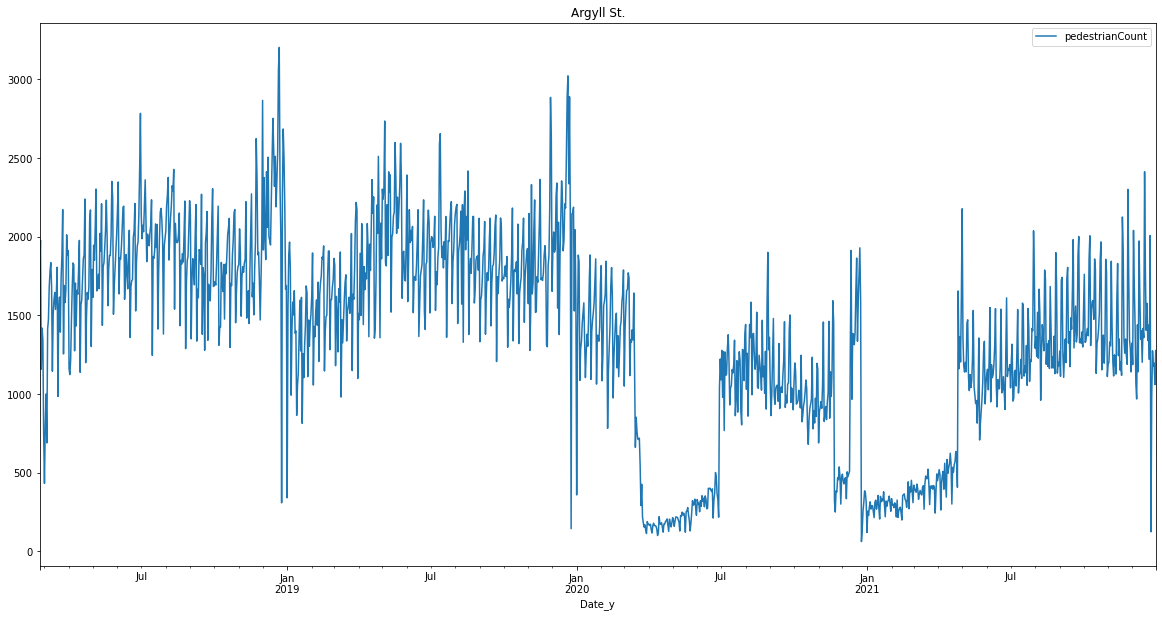

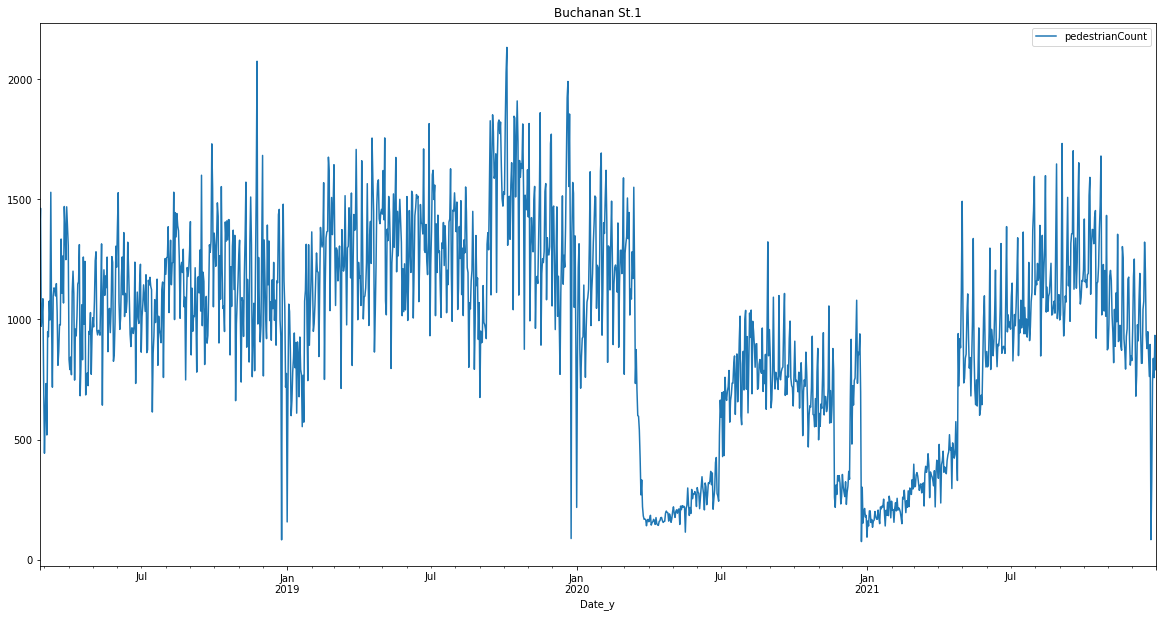

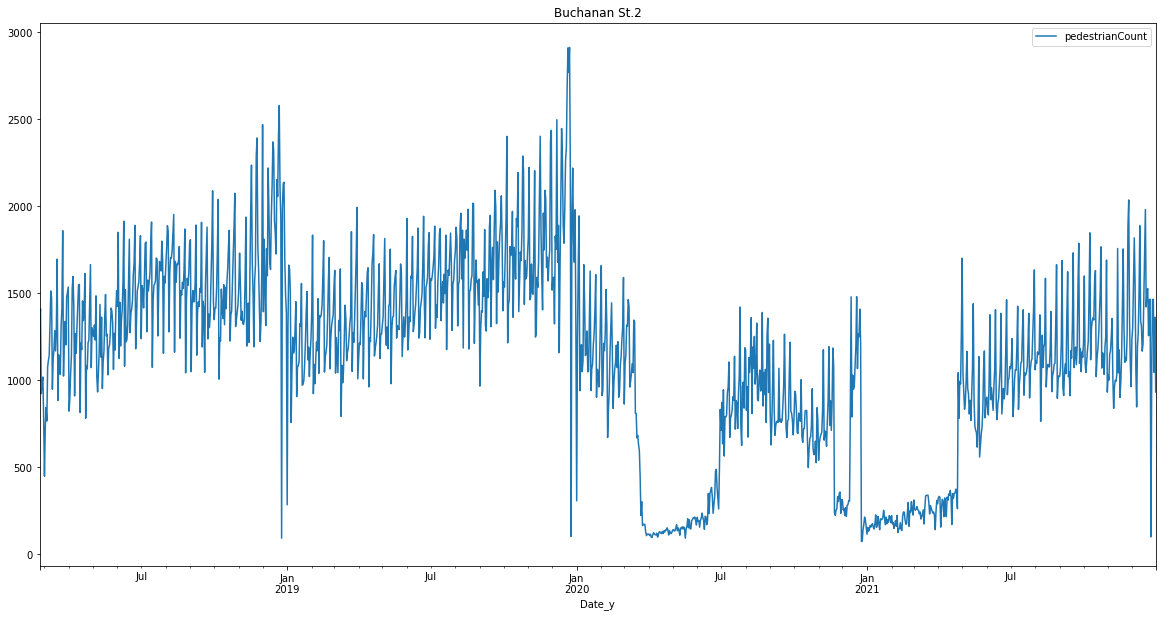

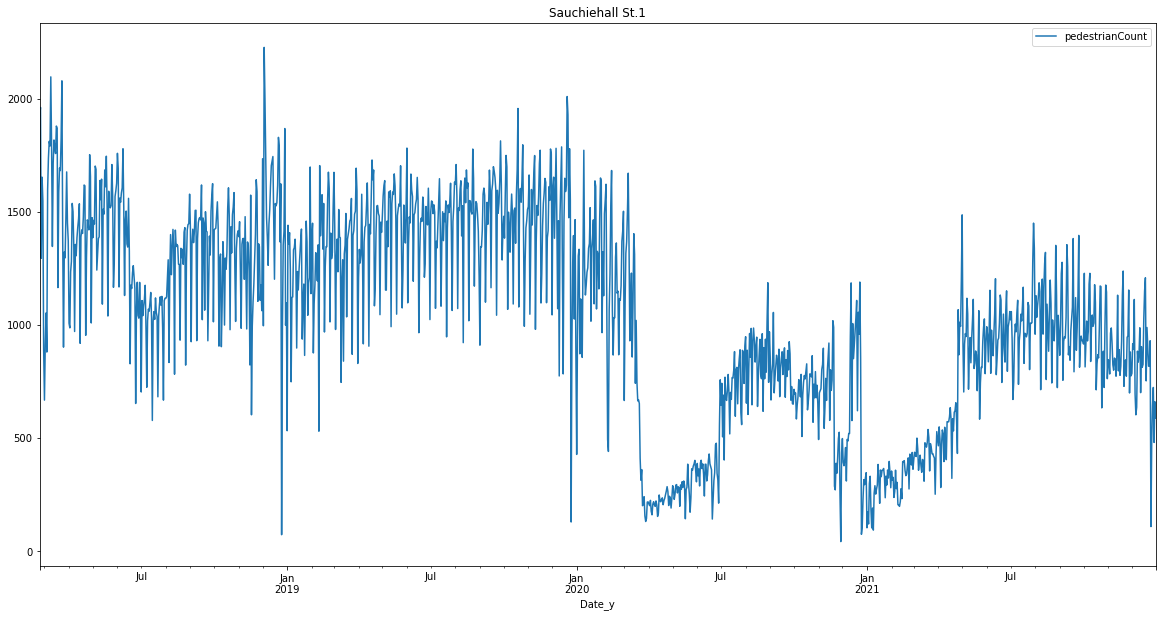

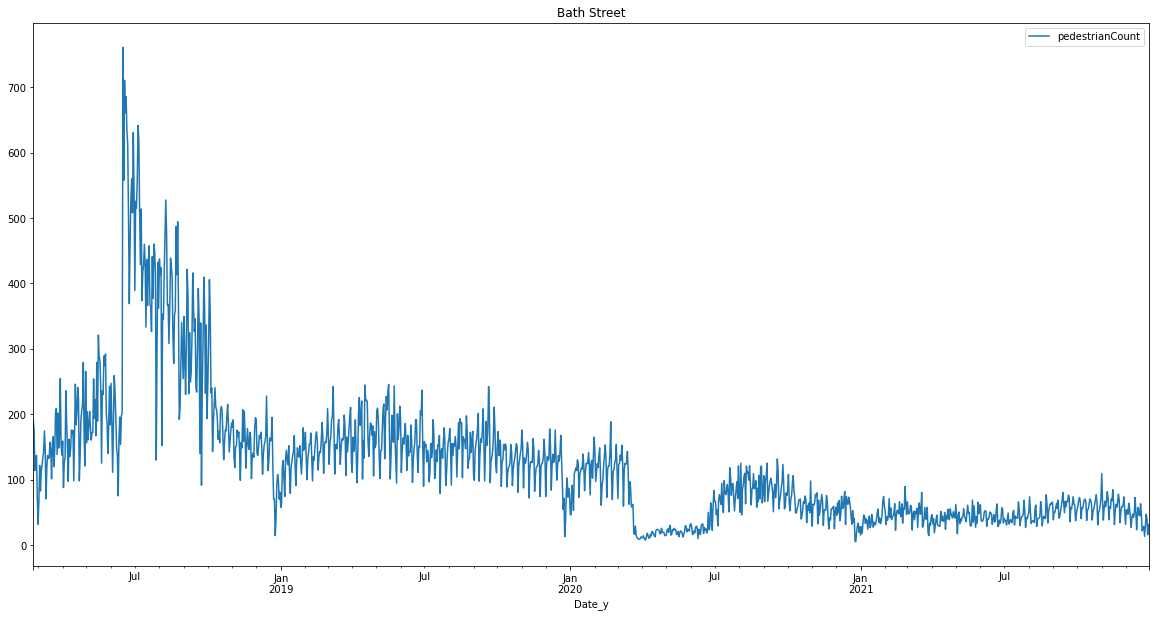

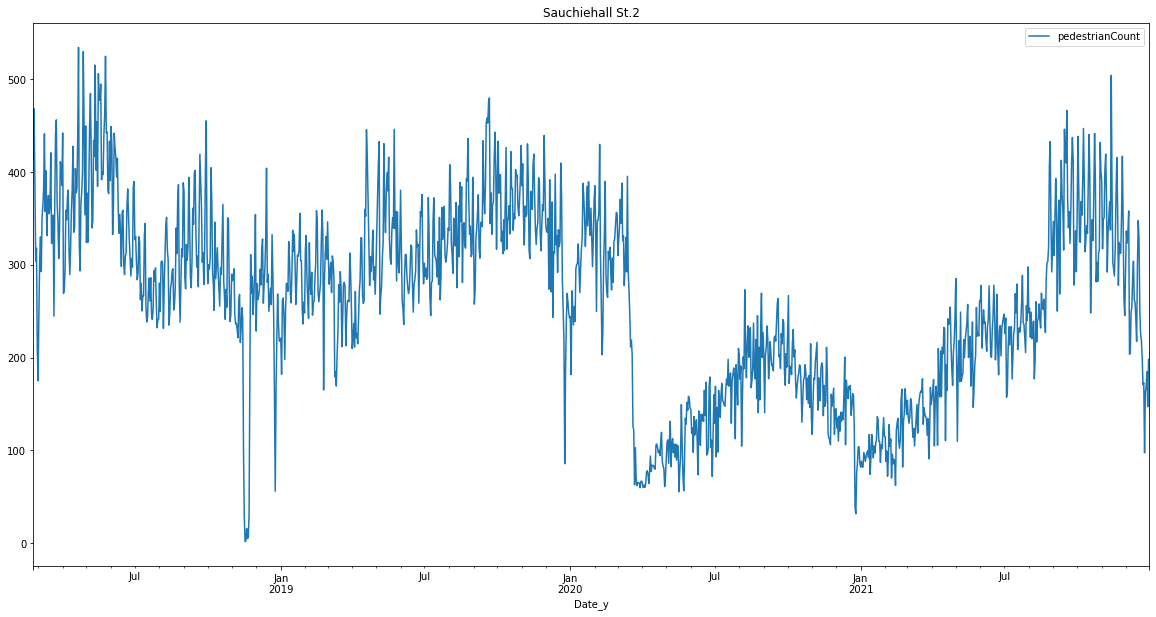

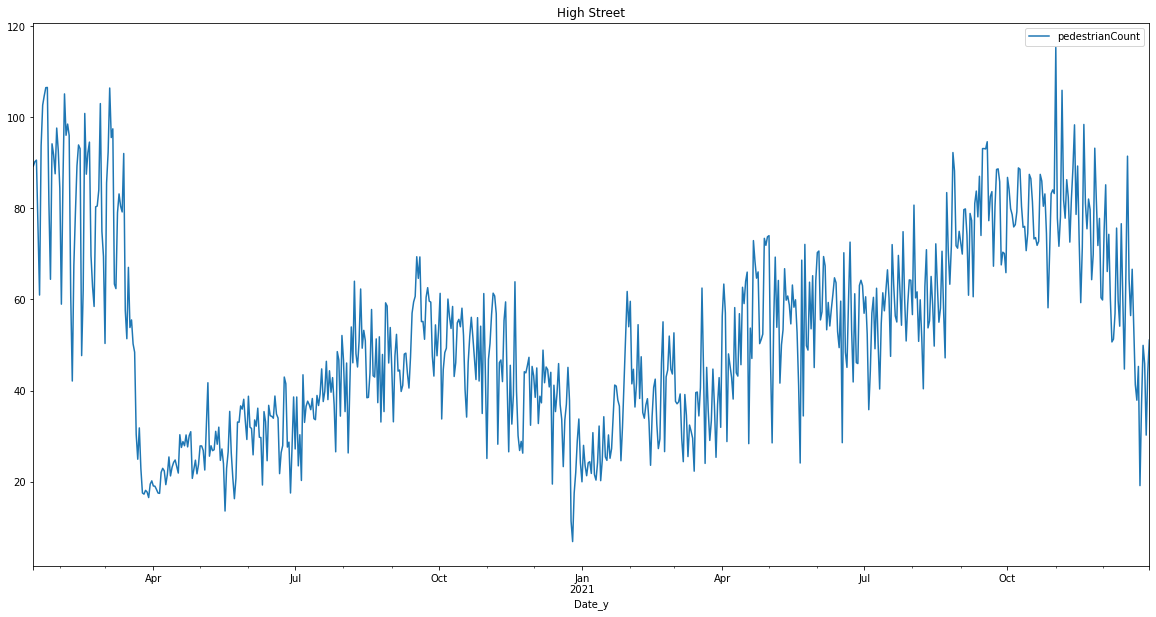

In [5]:
from turtle import title

# plotting time series with mean pedestrian count
temp_file = file.set_index('Date_y')
for i in temp_file.LocationName.unique():
    df_Footfall = temp_file[temp_file['LocationName']==i]
    # df_Footfall_year = df_Footfall['2017':'2023']
    df_Footfall.drop(df_Footfall.columns.difference(['Date_y','pedestrianCount']), 1, inplace=True)
    df_Footfall.resample('D').mean().plot(title=i,figsize=(20, 10))

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\3746018631.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


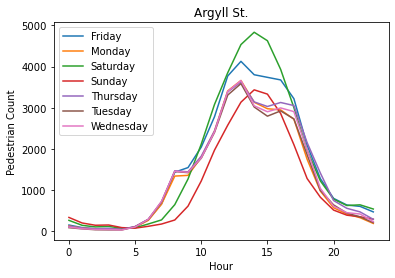

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\3746018631.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


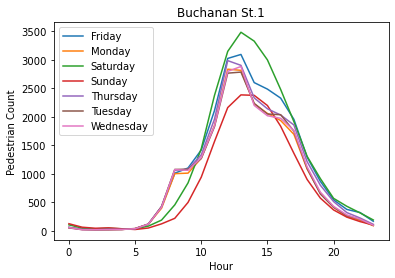

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\3746018631.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


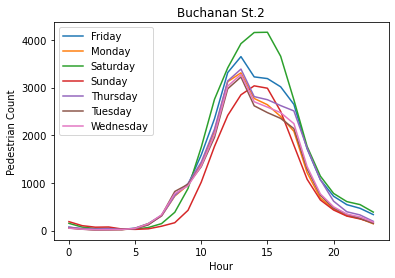

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\3746018631.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


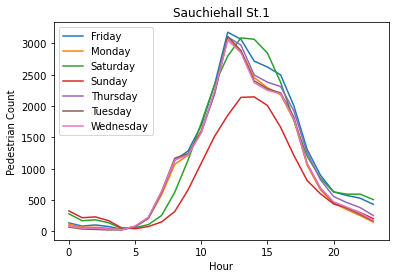

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\3746018631.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


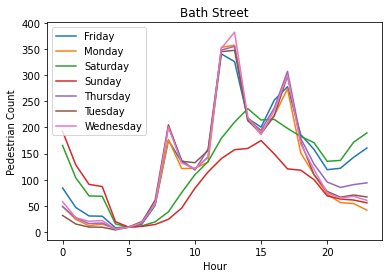

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\3746018631.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


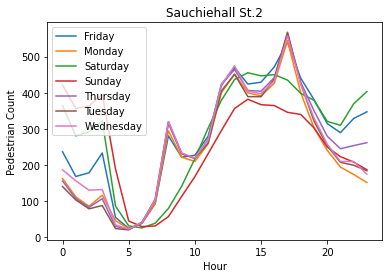

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\3746018631.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


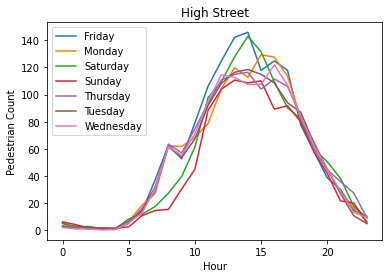

In [6]:
#plotting for the every hour in the week of the day
for index,location in enumerate(file.LocationName.unique()):
    temp = file[file['LocationName']==location]
    temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])
    file1 = temp.groupby(['Hour','Day_yr']).agg({'pedestrianCount': 'mean'}).reset_index()
    file1.set_index("Hour", inplace=True)
    file1.groupby("Day_yr")["pedestrianCount"].plot(legend=True, xlabel="Hour", ylabel="Pedestrian Count", title=location)
    plt.show()

In [7]:
# method to plot the on each of the variable for all the location
def showGrouByPlot(groupByVariable, location):
    df= file[file[groupByVariable] != 0]
    temp = df[df['LocationName']==location]
    days = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday', 'Sunday']
    if groupByVariable =='Day_yr':
        temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])
        file1 = temp.groupby([groupByVariable])['pedestrianCount'].sum().reindex(days)
    else:
        file1 = temp.groupby([groupByVariable])['pedestrianCount'].sum()
    return file1 

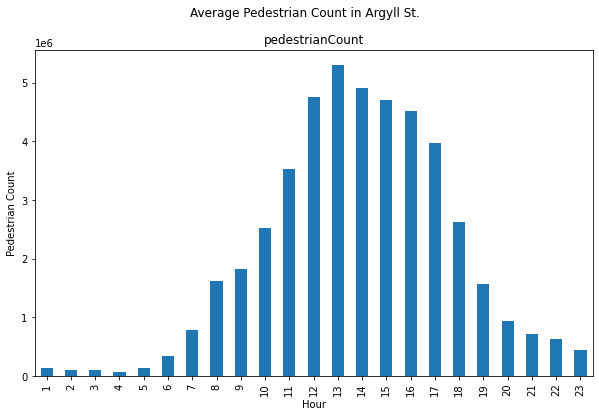

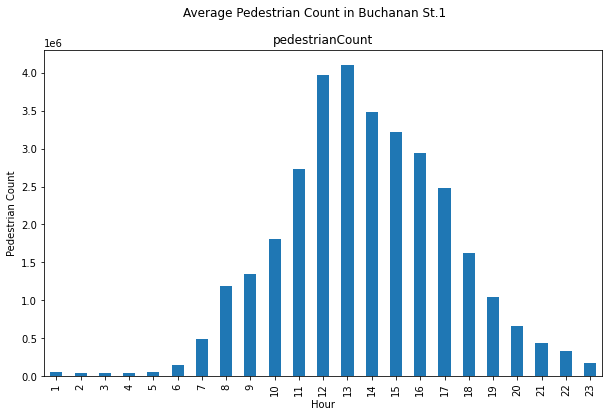

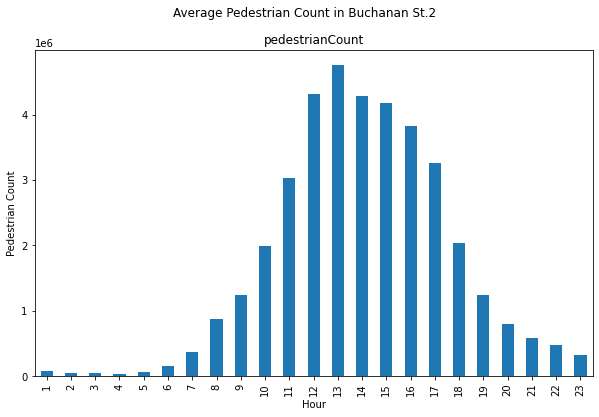

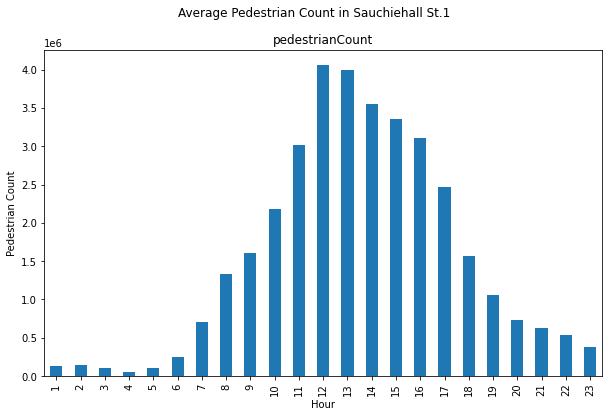

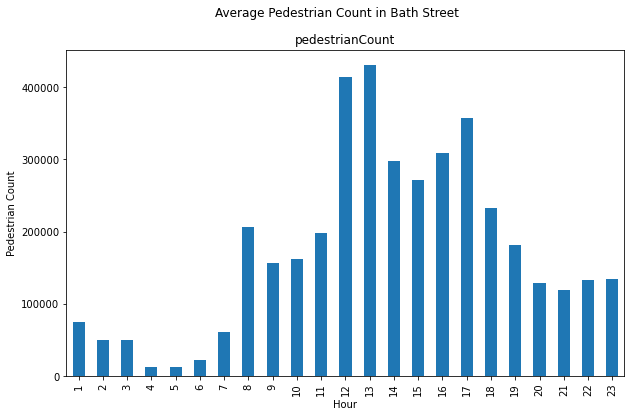

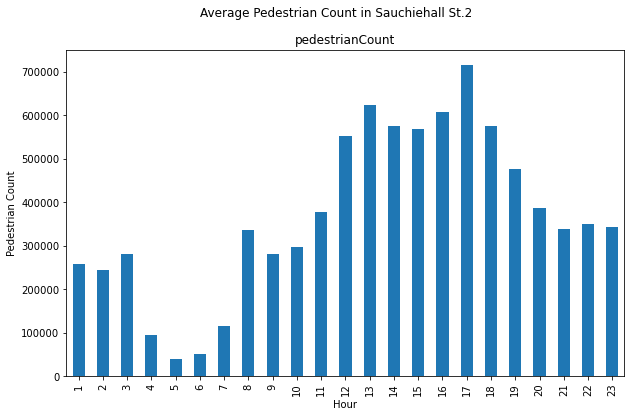

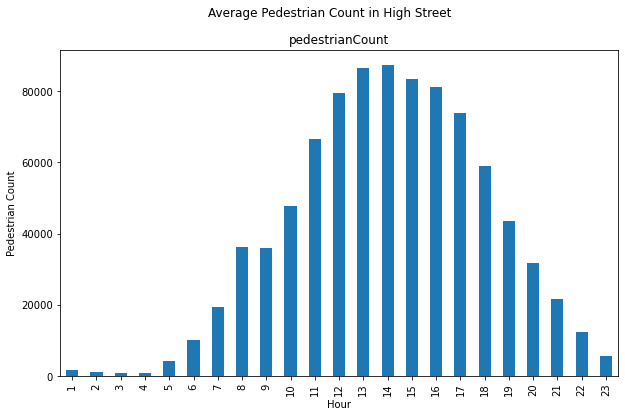

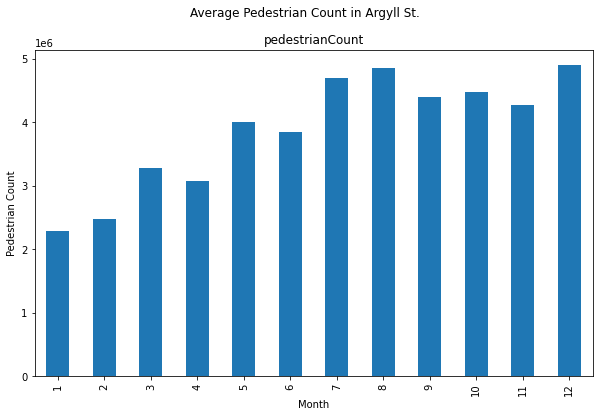

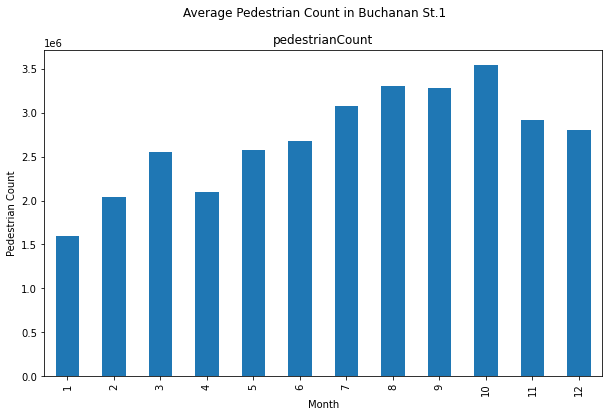

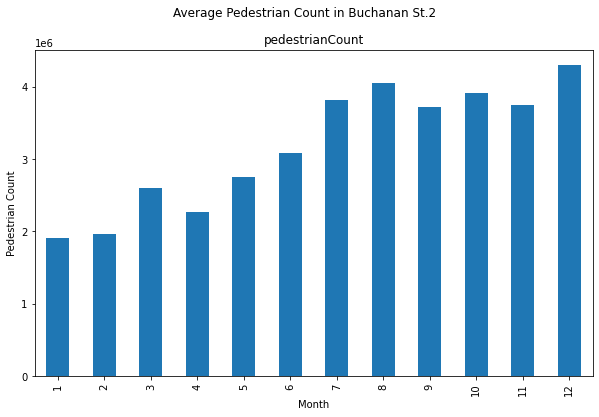

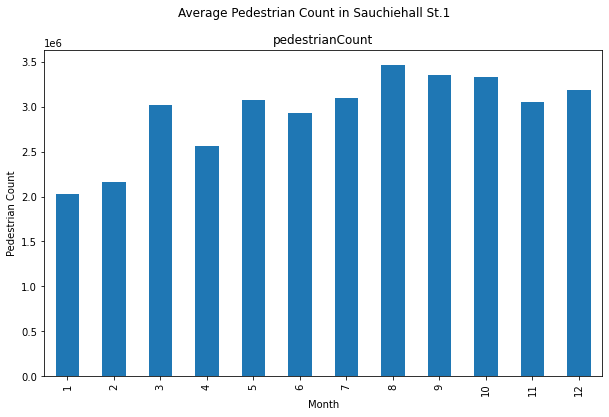

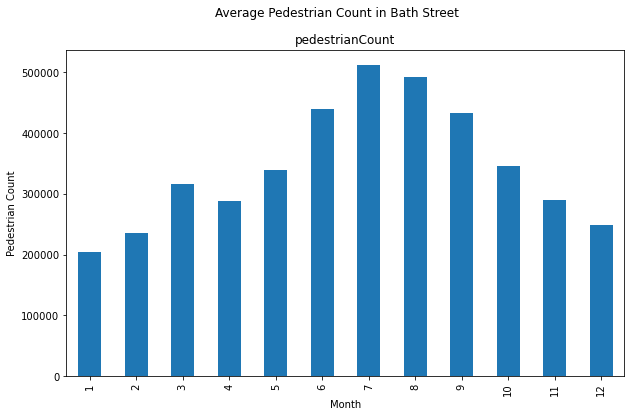

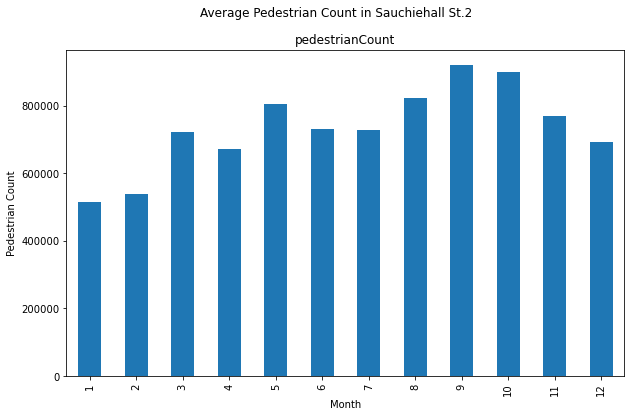

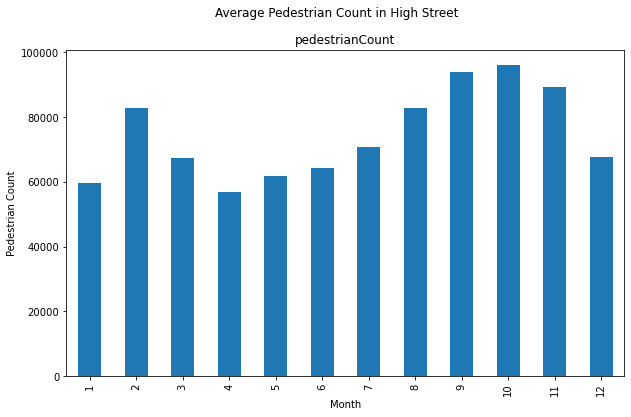

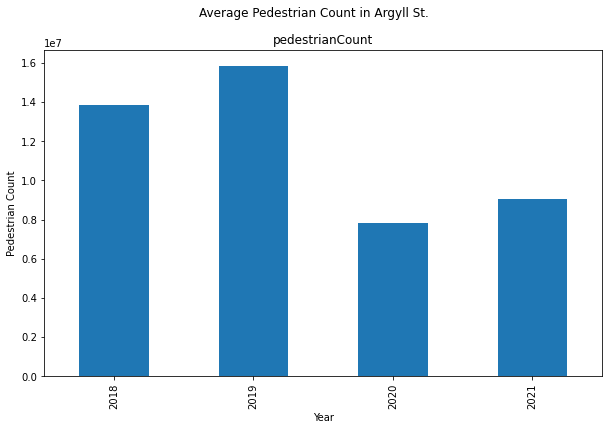

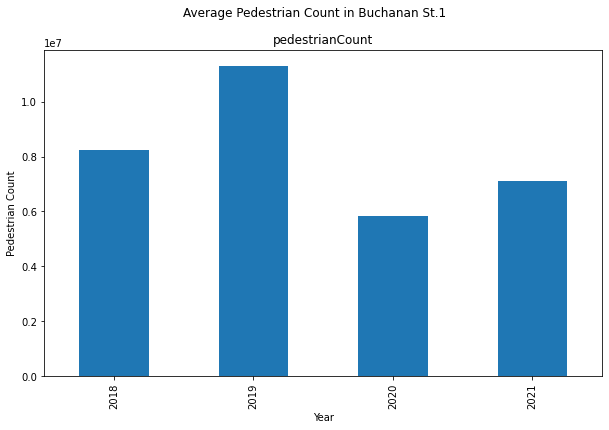

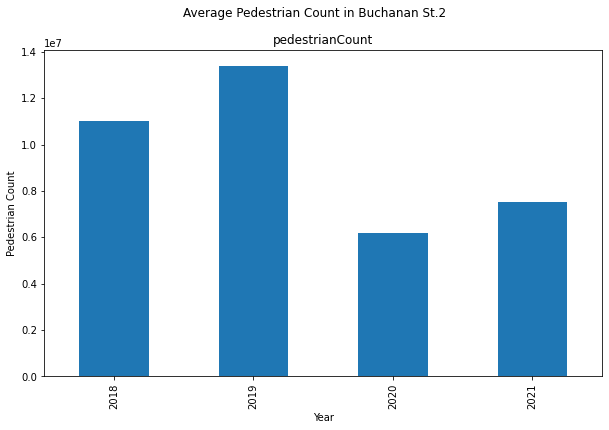

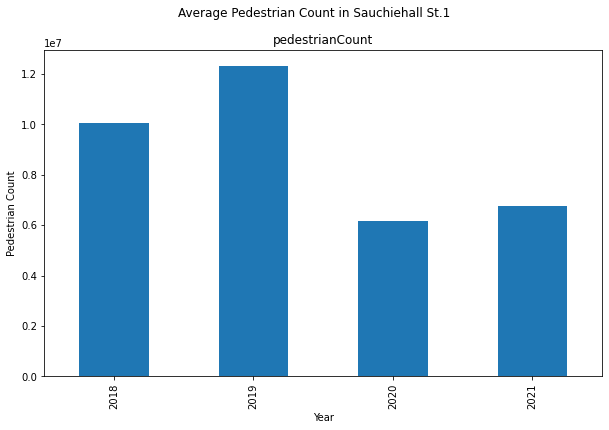

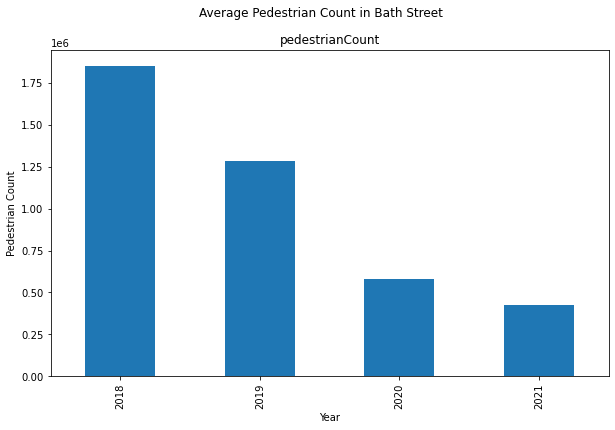

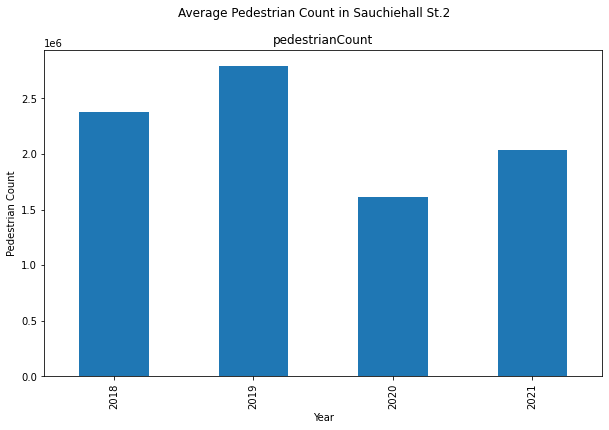

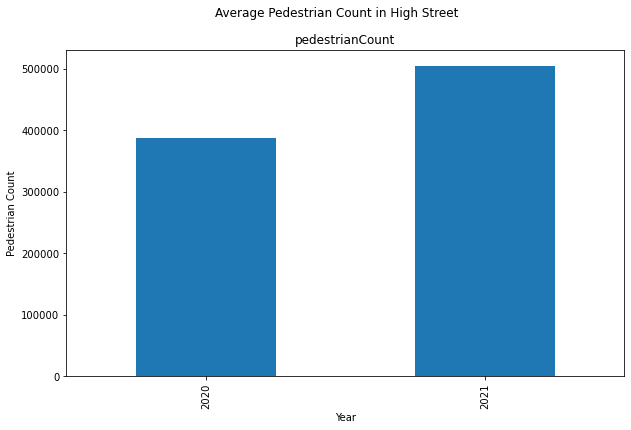

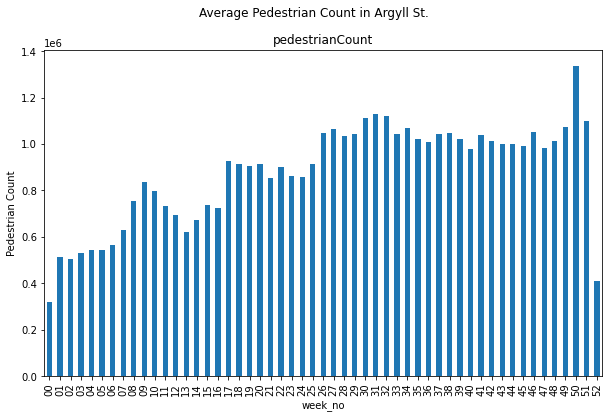

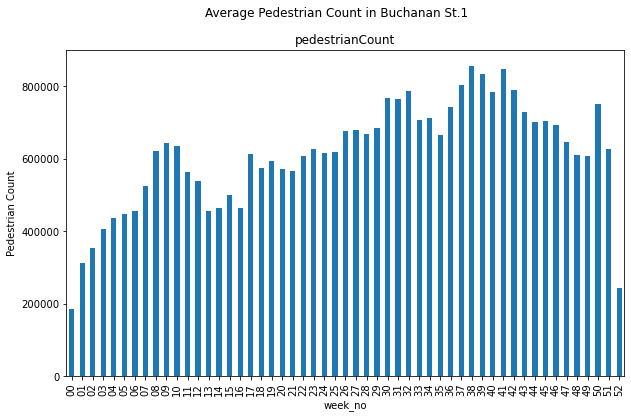

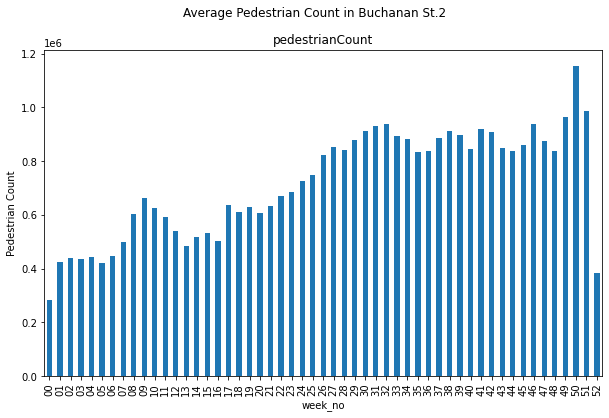

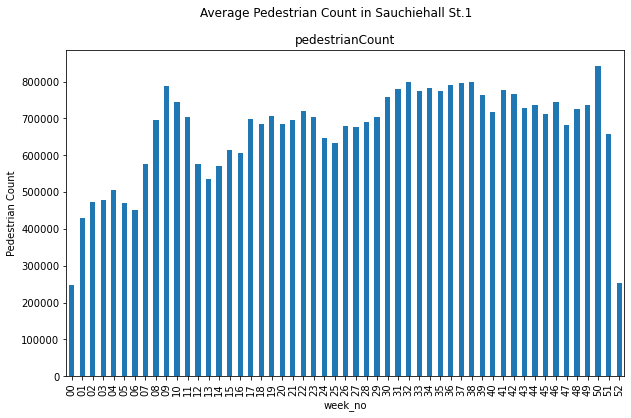

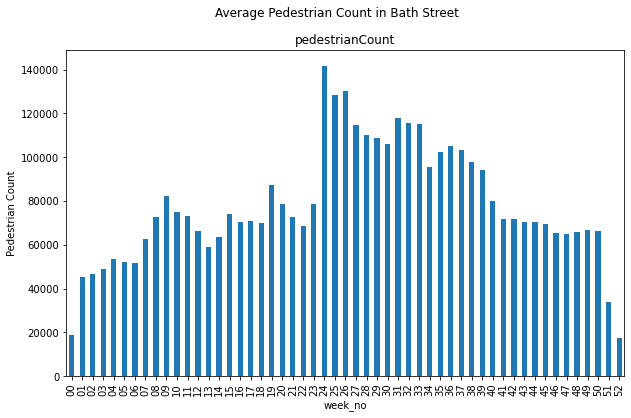

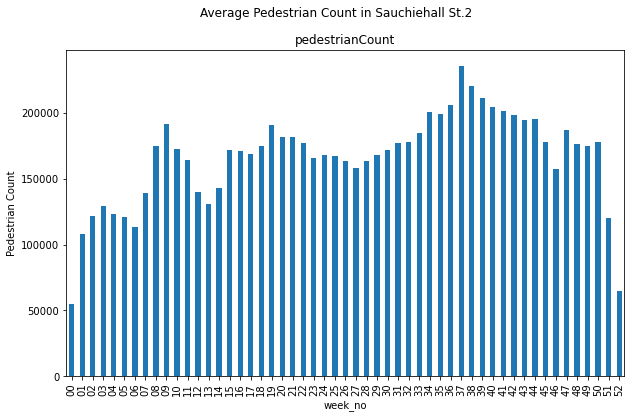

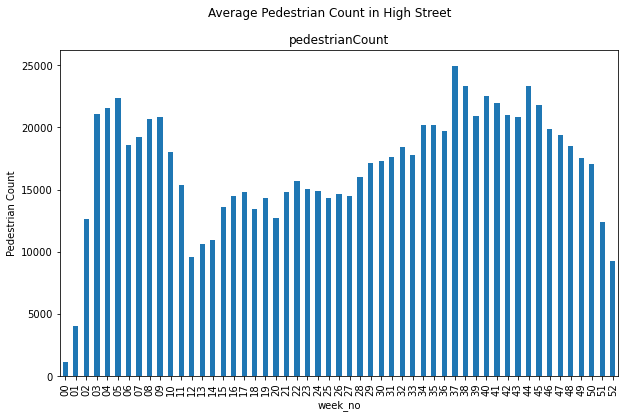

C:\Users\Bagya\AppData\Local\Temp\ipykernel_8404\32889750.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['Day_yr'] = temp['Day_yr'].apply(lambda x: x.split('/')[0])


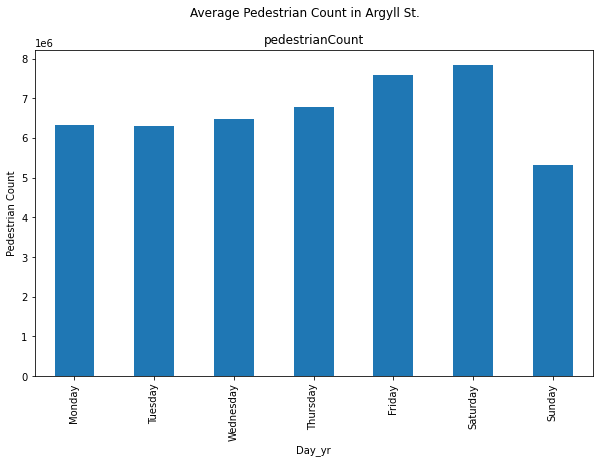

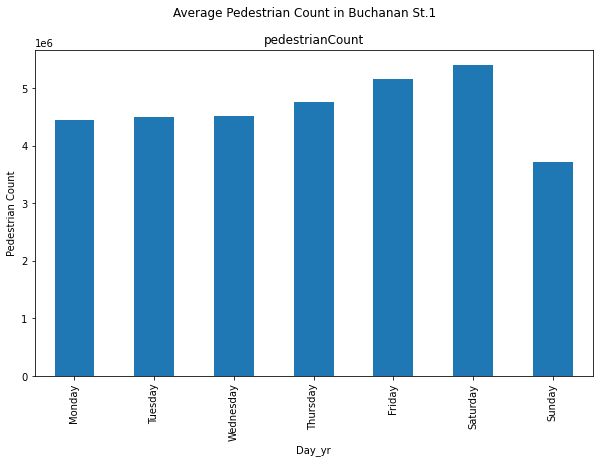

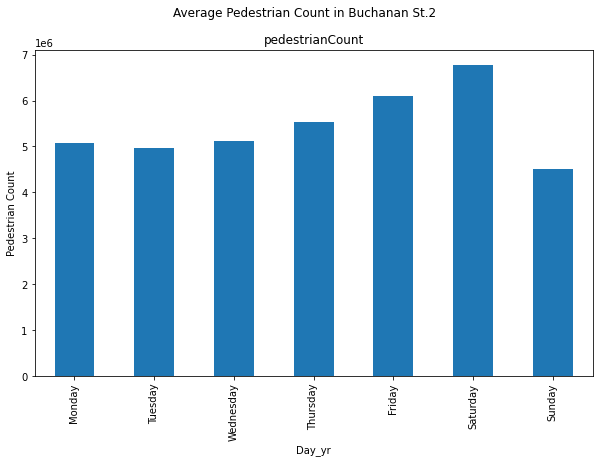

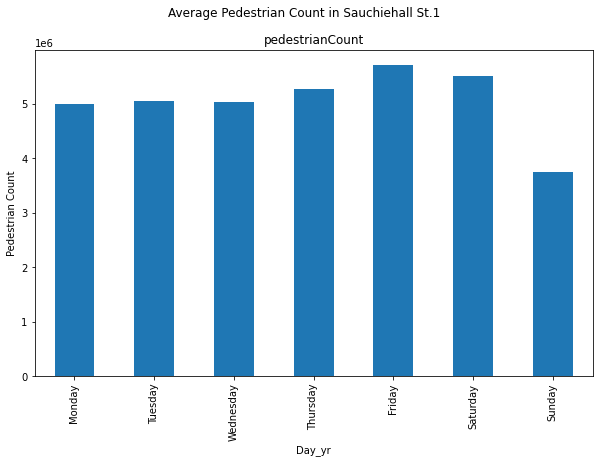

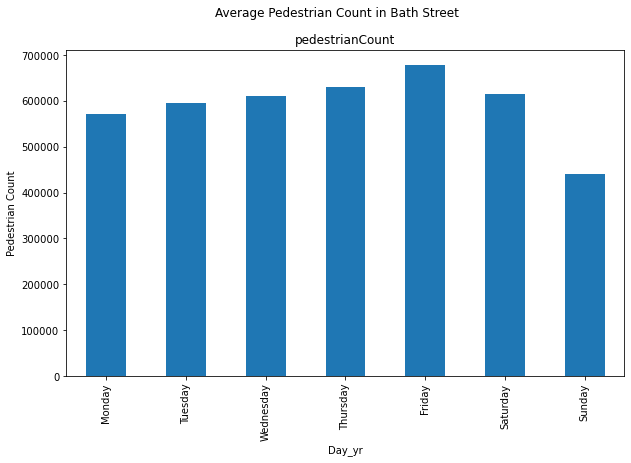

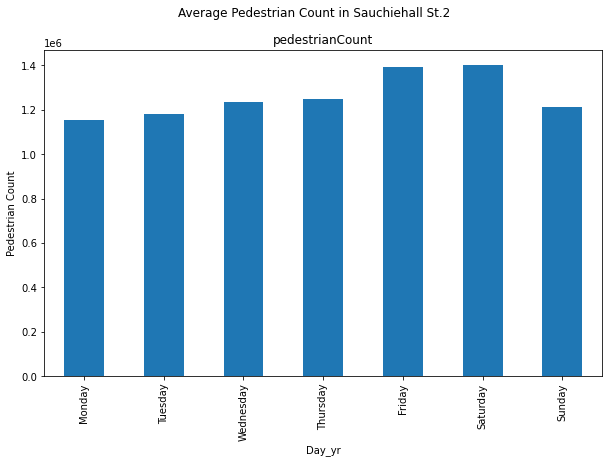

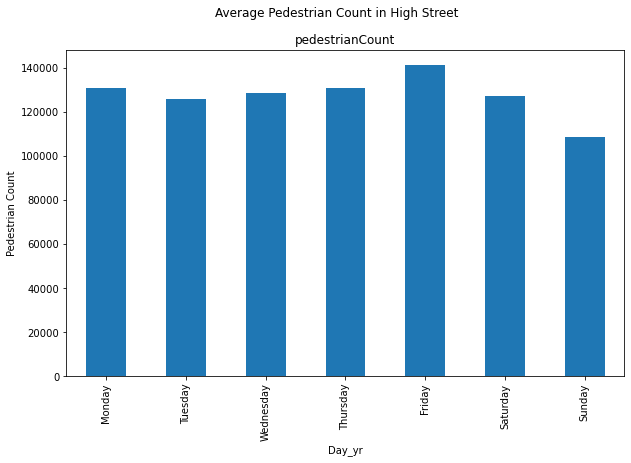

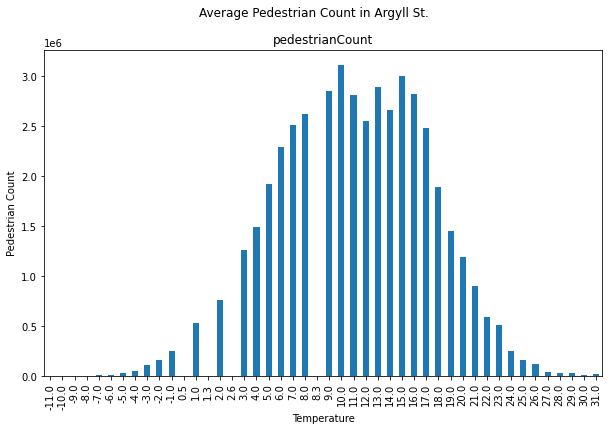

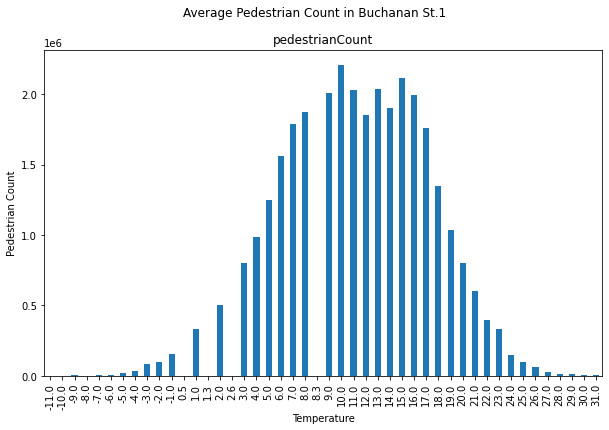

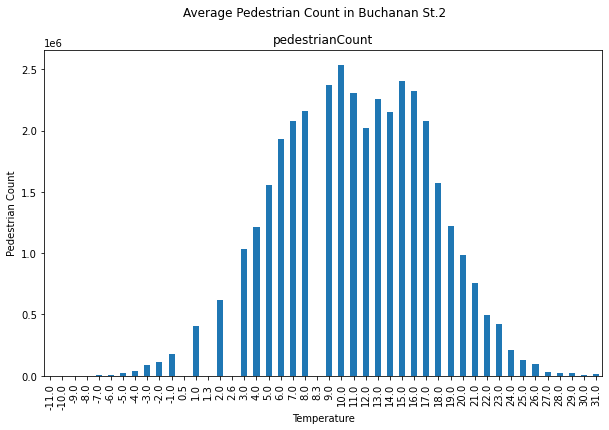

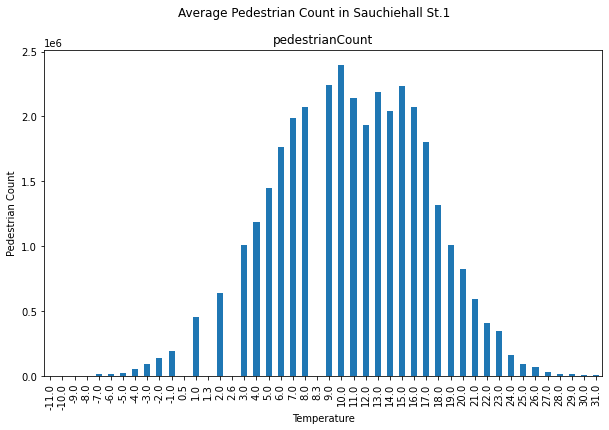

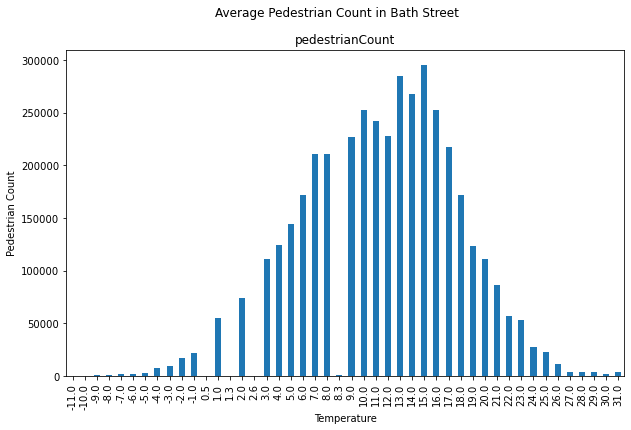

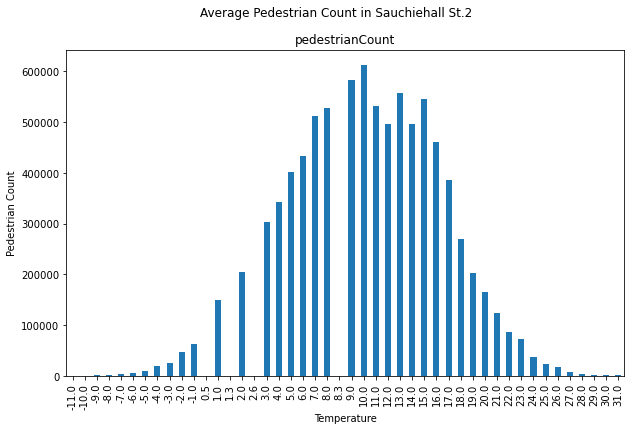

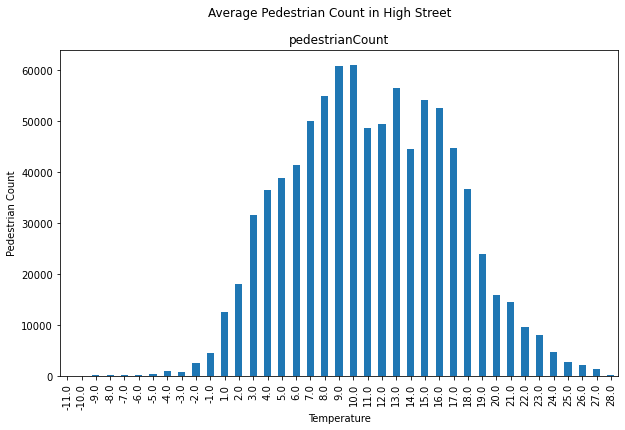

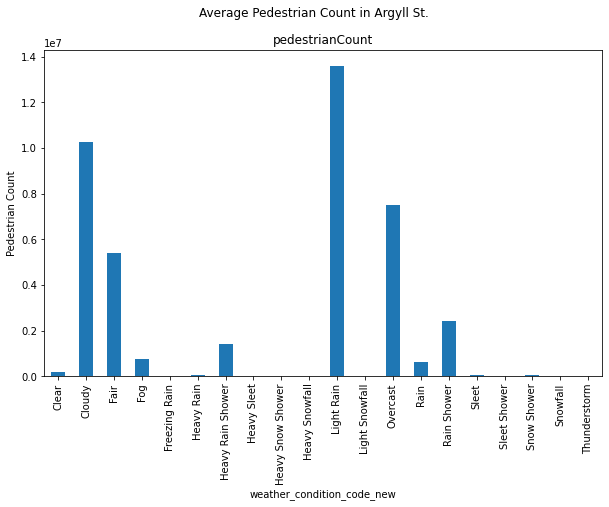

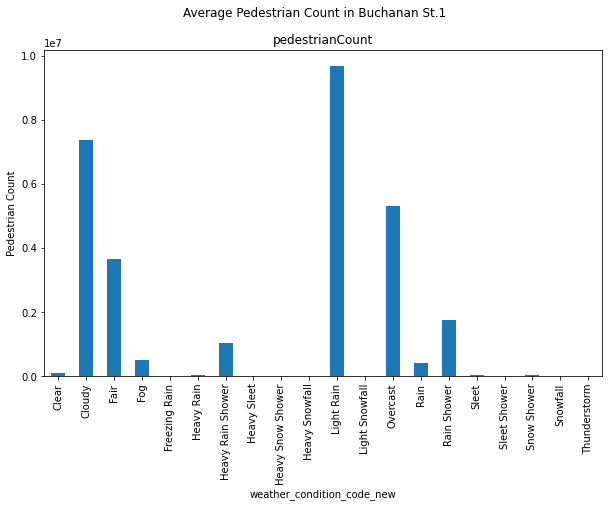

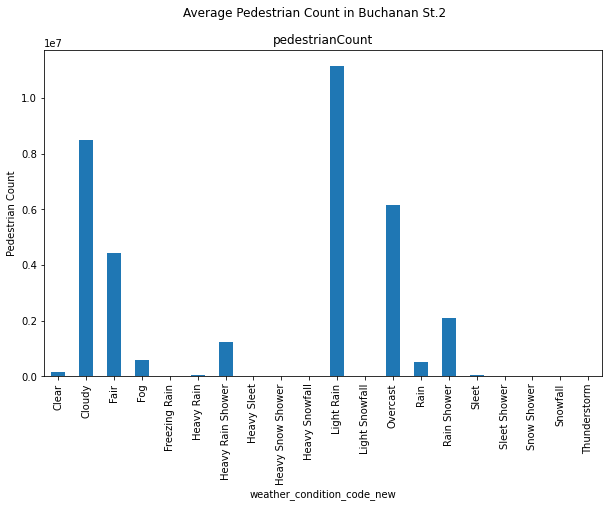

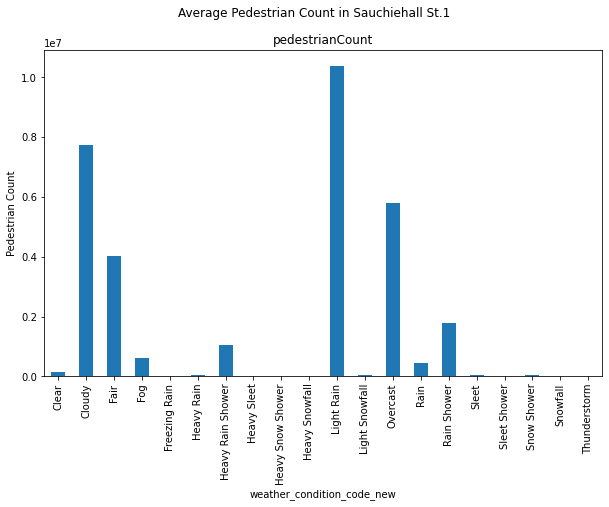

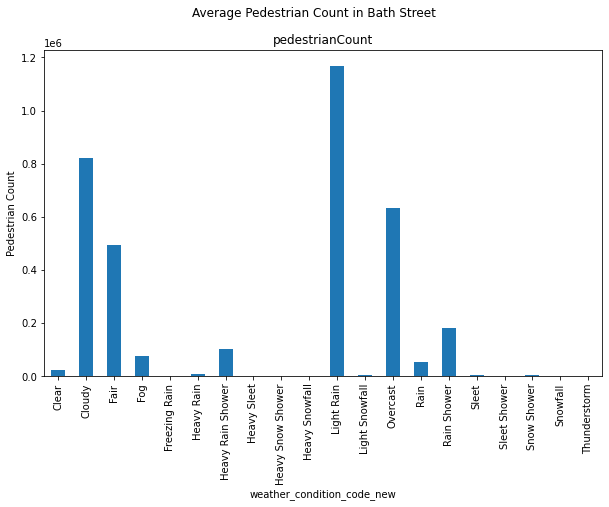

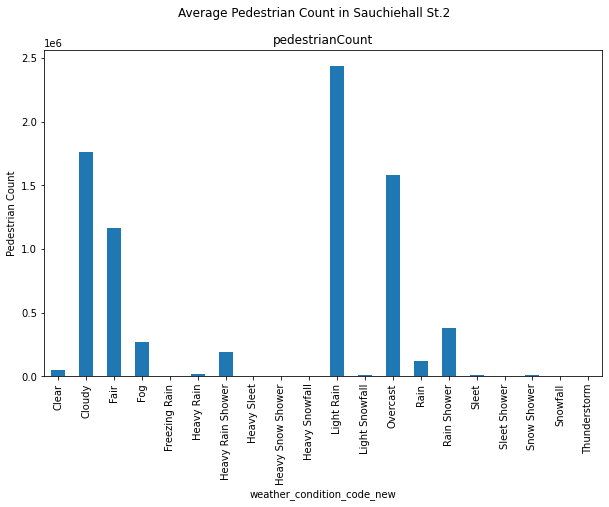

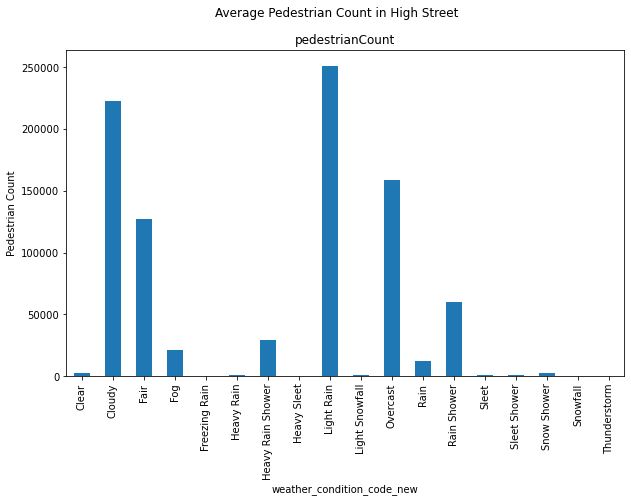

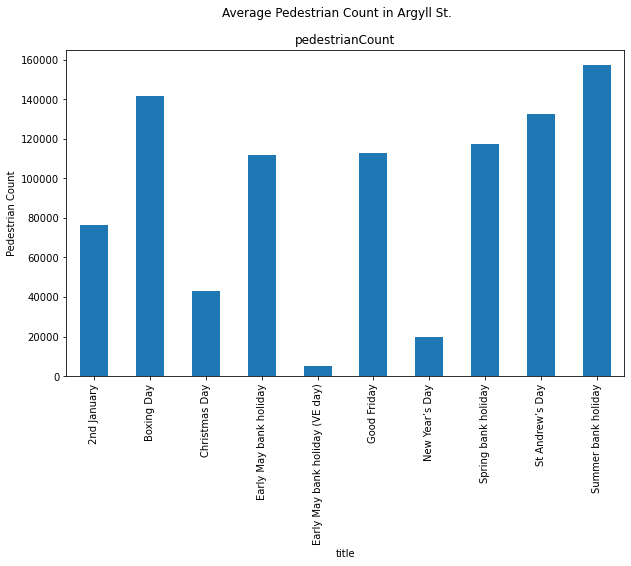

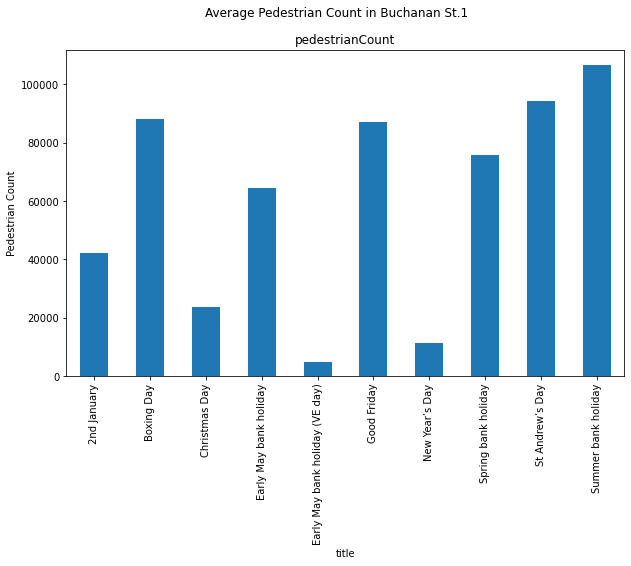

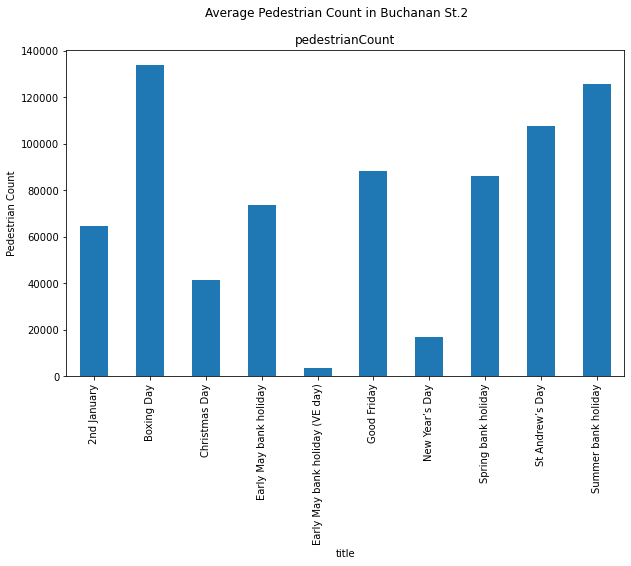

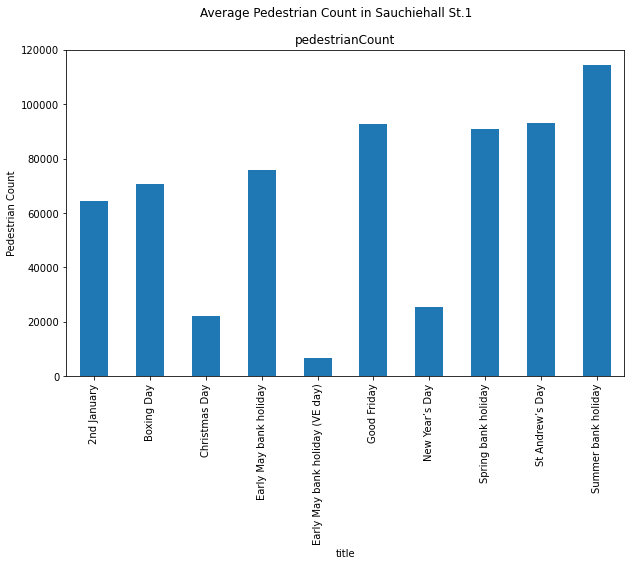

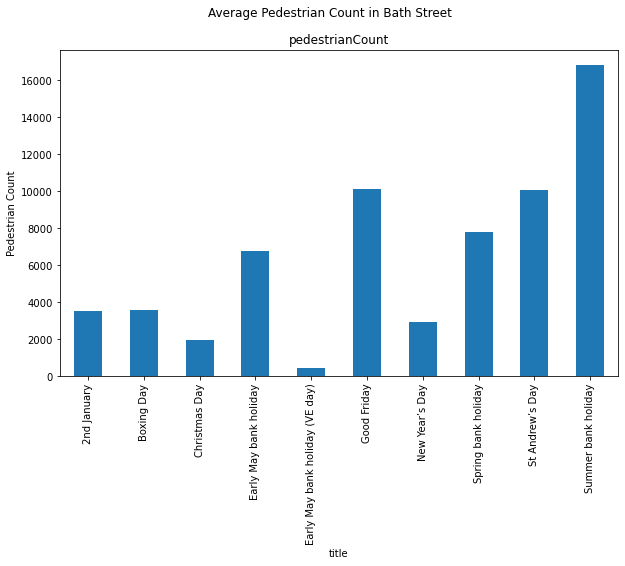

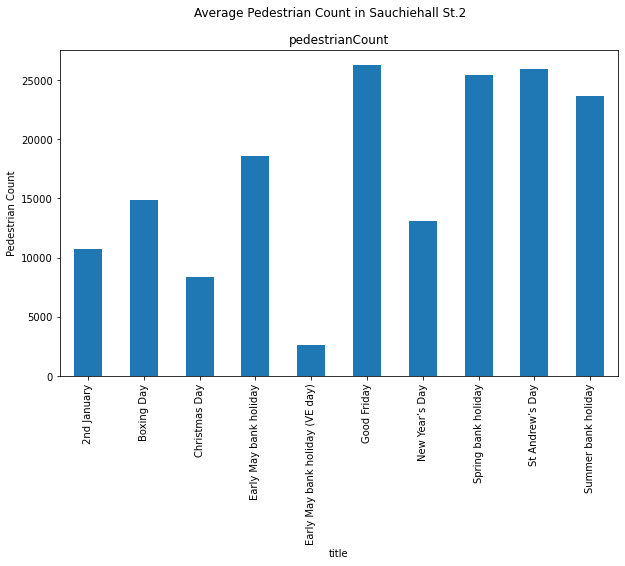

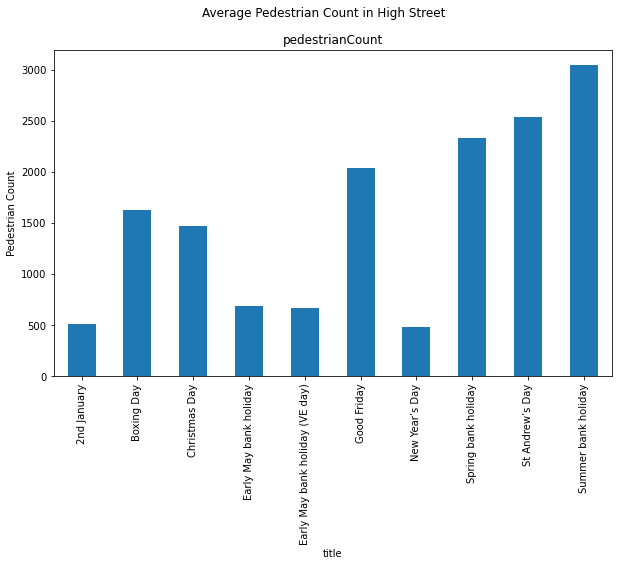

In [8]:
# plotting for the defined variables
groubyVariable = ['Hour','Month','Year','week_no','Day_yr','Temperature','weather_condition_code_new','title' ]
for key,variable in enumerate(groubyVariable) :
    for index,location in enumerate(file.LocationName.unique()):
        n = showGrouByPlot(variable,location)
        n.plot(kind='bar', title='Average Pedestrian Count in '+ location,
               ylabel='Pedestrian Count', xlabel=variable , subplots=True,figsize=(10, 6))
        plt.xticks(rotation=90)
        plt.show()

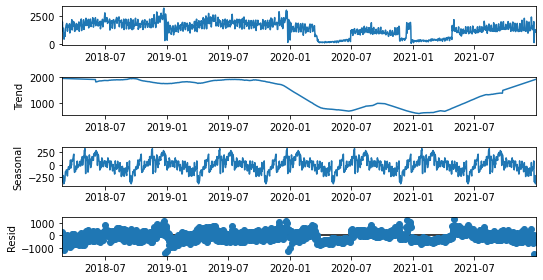

In [23]:
#time series decomposition

df = pd.read_csv(FOOTFALL_FILE)
location_dict = {"Argyll Street near Queen Street Junction" : "Argyll St." , "Buchanan Street near Buchanan Galleries Entrance" : "Buchanan St.1",
    "Buchanan Street near Gordon Street Junction" : "Buchanan St.2", "Sauchiehall Street near Wellington Street Junction" : "Sauchiehall St.1",
     "194 Bath Street (near Blythswood Street Junction)" : "Bath Street", "Sauchiehall Street near Elmbank Street Junction" : "Sauchiehall St.2",
     "253 High Street (near George Street Junction)" : "High Street" }
df['LocationName'] = df['LocationName'].map(location_dict) 
if 'ProccessedDate' not in df:
            df['ProccessedDate'] = pd.to_datetime(df["processDate"]).apply(lambda x: x.date())
temp = df[df['LocationName']=='Argyll St.']
temp = temp.groupby(['ProccessedDate','LocationName']).agg({'pedestrianCount': 'mean'}).reset_index()

filterred_df = temp[(temp['ProccessedDate']>datetime.date(2018,1,1)) & (temp['ProccessedDate']<datetime.date(2022,1,1))] 
filterred_df = filterred_df.set_index('ProccessedDate')
filterred_df.drop(filterred_df.columns.difference(['ProccessedDate','pedestrianCount']), 1, inplace=True)
result = sm(filterred_df,extrapolate_trend='freq', period=200)
fig = result.plot()
fig.set_figheight(4)
fig.set_figwidth(8)
plt.show()

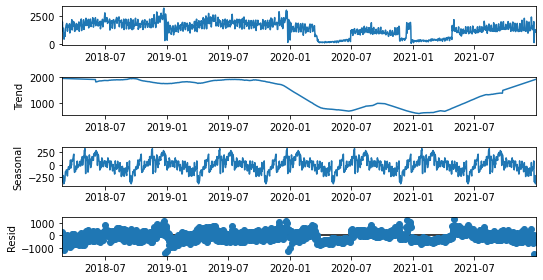

In [27]:
#Checking the time series decompostion for additive
result1 = sm(filterred_df, model='additive', extrapolate_trend='freq', period=200 )
fig = result1.plot()
fig.set_figheight(4)
fig.set_figwidth(8)
plt.show()

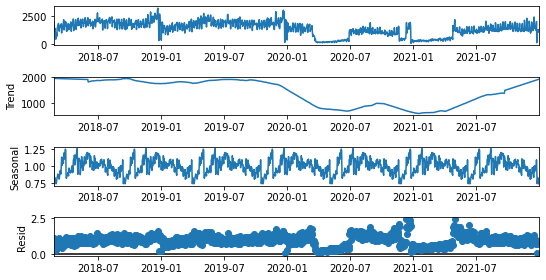

In [25]:
#Checking the time series decompostion for multiplicative

result2 = sm(filterred_df, model='multiplicative', extrapolate_trend='freq', period=200 )
fig = result2.plot()
fig.set_figheight(4)
fig.set_figwidth(8)
plt.show()

In [29]:
# Using ADFuller test to check the data is stationary or not
from statsmodels.tsa.stattools import adfuller
temp = file[file['LocationName']=='Argyll St.']
temp.drop(temp.columns.difference(['Date_y','pedestrianCount']), 1, inplace=True)
temp = temp.set_index('Date_y')
temp.resample('D').mean()
test_result=adfuller(temp['pedestrianCount'])
test_result


C:\Users\Bagya\anaconda3\envs\Python38\Lib\site-packages\pandas\core\frame.py:4308: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return super().drop(


(-7.686345830558444,
 1.458190032521166e-11,
 52,
 33739,
 {'1%': -3.4305438349564272,
  '5%': -2.861625670159991,
  '10%': -2.5668155995511652},
 482746.6698061167)

In [30]:
# showing the statistics value
print('ADF Statistic: %f' % test_result[0])
print('p-value: %f' % test_result[1])
print('Critical Values:')
for key, value in test_result[4].items():
	print('\t%s: %.3f' % (key, value))

ADF Statistic: -7.686346
p-value: 0.000000
Critical Values:
	1%: -3.431
	5%: -2.862
	10%: -2.567


In [127]:
#Adfuller test
def adfuller_test(sales):
    result=adfuller(sales)
    labels = ['ADF Test Statistic','p-value','#Lags Used','Number of Observations Used']
    for value,label in zip(result,labels):
        print(label+' : '+str(value) )
    if result[1] <= 0.05:
        print("strong evidence against null hypothesis(Ho), we can now reject null hypothesis. Data has no unit root and is stationary")
    else:
        print("weak evidence against null hypothesis, we can not reject null hypothesis. time series has a unit root, telling that it is non-stationary ")
adfuller_test(temp['pedestrianCount'])


ADF Test Statistic : -7.686345830558444
p-value : 1.458190032521166e-11
#Lags Used : 52
Number of Observations Used : 33739
strong evidence against the null hypothesis(Ho), reject the null hypothesis. Data has no unit root and is stationary
